# 3D Jerk-Controlled Lattice Planning in JAX — Part 2: Multi-Cylinder Slalom, LQMT Heuristics & Pure-JAX Search

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_lattice_search_3d_jerk_jax_colab.ipynb)

This second companion notebook implements **Sections III-C, III-D (Proposition 3), and Figs. 5 & 8** of Liu et al. (2017), *Search-based Motion Planning for Quadrotors using Linear Quadratic Minimum Time Control* (`lattice_quad.pdf`), for a **jerk-controlled quadrotor ($n = 3$) weaving through a 6-cylinder slalom course** at constant altitude $z_0 = 1.0\,\text{m}$ ($u_z = 0$, $M = 9$ horizontal jerk primitives):

1. **Problem 2 — Discrete Graph Search on the Jerk Lattice (Sec. III-C)**: Starting from a moving state $\mathbf{s}_0 = [\mathbf{p}_0, \mathbf{v}_0, \mathbf{a}_0]^\top \in \mathbb{R}^{3 \times 3}$ with diagonal initial velocity $\mathbf{v}_0 = [0.5, 0.5, 0]^\top\,\text{m/s}$ aimed directly toward an obstacle, we search over sequences of constant-jerk primitives $\mathbf{u}_k \in \mathcal{U}_9 = \{-j_{\max}, 0, +j_{\max}\}^2 \times \{0\}$ of duration $\tau = 0.5\,\text{s}$ to reach $\mathbf{s}_g$ at the end of a 3-gate cylindrical slalom corridor while minimizing cumulative jerk effort plus time:
   $$\min_{\{\mathbf{u}_k\}_{k=0}^{N-1}} \sum_{k=0}^{N-1} \left(\|\mathbf{u}_k\|_2^2 + \rho\right)\tau.$$
2. **Block 1 — Admissible Heuristics $h_1$ (Min-Time) vs. $h_2$ (LQMT, Sec. III-D & Proposition 3)**: Compares the kinematic lower bound $h_1(\mathbf{s}) = \rho \bar{T}_v$ against the explicit Linear Quadratic Minimum-Time (LQMT) cost-to-go $h_2(\mathbf{s})$ computed via the $3 \times 3$ controllability Gramian $W_T$.
3. **Block 2 — Fully Tensorized Pure-JAX Wavefront Search (`jax.lax.while_loop`, Figs. 5 & 8)**: Executes Dijkstra ($h = 0$), $A^*$ with $h_1$, and $A^*$ with $h_2$ entirely inside XLA over fixed-capacity arrays (zero Python `heapq`), achieving a **$50.6\times$ reduction in expanded lattice nodes** ($1316 \to 26$) on the 8-stage ($T^* = 4.0\,\text{s}$) multi-obstacle S-curve slalom.


In [1]:
import importlib.util
import subprocess
import sys
import time

_missing = []
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    _missing.append("jax")

if importlib.util.find_spec("matplotlib") is None:
    _missing.append("matplotlib")

if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle

# Preserve full float32 precision on CUDA GPUs (disable TF32 matmul rounding)
jax.config.update("jax_default_matmul_precision", "highest")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
})

# Multi-Cylinder Horizontal Slalom Jerk Lattice Kernel (n = 3, z = z0 = 1.0 m, M = 9 primitives)
tau = 0.5
j_max = 2.0
v_max = 1.0
a_max = 1.0
rho = 12.0
z0 = 1.0

u_1d = jnp.array([-j_max, 0.0, j_max])
ugx, ugy = jnp.meshgrid(u_1d, u_1d, indexing="ij")
U_M = jnp.stack([ugx.reshape(-1), ugy.reshape(-1), jnp.zeros(9)], axis=-1)  # (9, 3)
EDGE_COSTS = (jnp.sum(U_M**2, axis=-1) + rho) * tau                         # (9,)


def F_mat(t):
    return jnp.array([
        [1.0, t, 0.5 * t**2],
        [0.0, 1.0, t],
        [0.0, 0.0, 1.0],
    ])


def G_vec(t):
    return jnp.array([t**3 / 6.0, 0.5 * t**2, t])


# 6 Tall Cylindrical Obstacles (z in [0.0, 2.0] m) forming 3 staggered slalom gates
cyl_xy = jnp.array([
    [0.75,  0.42],   # Gate 1 upper cylinder (blocks initial +y velocity)
    [0.85, -0.38],   # Gate 1 lower cylinder
    [1.75,  0.18],   # Gate 2 upper cylinder (forces S-curve down to y = -0.21)
    [1.75, -0.58],   # Gate 2 lower cylinder
    [2.75, -0.18],   # Gate 3 lower cylinder (forces S-curve back up to y = +0.25)
    [2.75,  0.62],   # Gate 3 upper cylinder
])
cyl_radii = jnp.array([0.22, 0.22, 0.24, 0.22, 0.24, 0.22])
cyl_z_min, cyl_z_max = 0.0, 2.0
t_check = jnp.linspace(0.0, tau, 11)


def eval_primitive(s, u):
    return jax.vmap(lambda t: F_mat(t) @ s + jnp.outer(G_vec(t), u))(t_check)


def get_successors(s):
    trajs = jax.vmap(eval_primitive, in_axes=(None, 0))(s, U_M)  # (9, 11, 3, 3)
    p_tr, v_tr, a_tr = trajs[:, :, 0, :], trajs[:, :, 1, :], trajs[:, :, 2, :]

    vel_ok = jnp.all(jnp.abs(v_tr[:, :, :2]) <= v_max + 1e-5, axis=(1, 2))
    acc_ok = jnp.all(jnp.abs(a_tr[:, :, :2]) <= a_max + 1e-5, axis=(1, 2))
    bounds_ok = (
        jnp.all((p_tr[:, :, 0] >= -0.05) & (p_tr[:, :, 0] <= 3.65), axis=1)
        & jnp.all((p_tr[:, :, 1] >= -0.55) & (p_tr[:, :, 1] <= 0.55), axis=1)
    )
    dists_xy = jnp.linalg.norm(p_tr[:, :, None, :2] - cyl_xy[None, None, :, :], axis=-1)
    obs_ok = jnp.all(dists_xy > cyl_radii[None, None, :], axis=(1, 2))

    valid = vel_ok & acc_ok & bounds_ok & obs_ok
    return trajs[:, -1, :, :], valid, EDGE_COSTS


# Start state (diagonal velocity toward Gate 1 Upper Cylinder) and Goal state at corridor exit
s0 = jnp.array([
    [0.0, 0.0, z0],    # p0 [m]
    [0.5, 0.5, 0.0],   # v0 [m/s]
    [0.0, 0.0, 0.0],   # a0 [m/s^2]
])
s_goal = jnp.array([
    [3.5, 0.25, z0],   # pg [m]
    [1.0, 0.0,  0.0],  # vg [m/s]
    [0.0, 0.0,  0.0],  # ag [m/s^2]
])


def is_goal(s):
    return jnp.max(jnp.abs(s[:, :2] - s_goal[:, :2])) < 1e-4


print(f"JAX version: {jax.__version__} | Backend: {jax.default_backend()} | Devices: {jax.devices()}")
print(f"Control lattice U_M: {U_M.shape}, Edge costs range: [{float(EDGE_COSTS.min()):.1f}, {float(EDGE_COSTS.max()):.1f}]")
print(f"Start state s0   -> pos={s0[0].tolist()}, vel={s0[1].tolist()}, acc={s0[2].tolist()}")
print(f"Goal state s_goal -> pos={s_goal[0].tolist()}, vel={s_goal[1].tolist()}, acc={s_goal[2].tolist()}")
print(f"Obstacles        -> {cyl_xy.shape[0]} vertical cylinders in z in [{cyl_z_min:.1f}, {cyl_z_max:.1f}] m")


JAX version: 0.6.2 | Backend: gpu | Devices: [CudaDevice(id=0)]
Control lattice U_M: (9, 3), Edge costs range: [6.0, 10.0]


Start state s0   -> pos=[0.0, 0.0, 1.0], vel=[0.5, 0.5, 0.0], acc=[0.0, 0.0, 0.0]
Goal state s_goal -> pos=[3.5, 0.25, 1.0], vel=[1.0, 0.0, 0.0], acc=[0.0, 0.0, 0.0]
Obstacles        -> 6 vertical cylinders in z in [0.0, 2.0] m


---
## Block 1: Admissible Heuristics $h_1$ (Min-Time) vs. $h_2$ (LQMT, Proposition 3)

To guide $A^*$ search through the 6-cylinder slalom without sacrificing optimality, Section III-D constructs lower bounds on the true cost-to-go $C^*(\mathbf{s}, \mathbf{s}_g)$ by relaxing obstacle and input-discretization constraints:

1. **Minimum-Time Heuristic $h_1$ (Eq. 7)**: Drops control effort ($\|\mathbf{u}\|_2^2 \ge 0$) and bounds the remaining flight time via the per-axis speed limit $v_{\max}$:
   $$h_1(\mathbf{s}) = \rho \bar{T}_v, \qquad \bar{T}_v = \frac{\|\mathbf{p}_g - \mathbf{p}\|_\infty}{v_{\max}}.$$
   Because $h_1$ depends only on position $\mathbf{p}$, it ignores whether the current velocity $\mathbf{v}$ and acceleration $\mathbf{a}$ are pointed toward or away from $\mathbf{s}_g$.

2. **Linear Quadratic Minimum-Time (LQMT) Heuristic $h_2$ (Proposition 3, Eq. 8–10)**: Solves the continuous-time unconstrained optimal control problem from $\mathbf{s}$ to $\mathbf{s}_g$ over horizon $T \ge \bar{T}_v$. For $n = 3$ jerk control at constant altitude $z_0$, the per-axis controllability Gramian $W_T = \int_0^T G(s)G(s)^\top ds$ and horizontal terminal state residual $\delta_T \in \mathbb{R}^{3 \times 2}$ are:
   $$W_T = \begin{bmatrix} \frac{T^5}{20} & \frac{T^4}{8} & \frac{T^3}{6} \\ \frac{T^4}{8} & \frac{T^3}{3} & \frac{T^2}{2} \\ \frac{T^3}{6} & \frac{T^2}{2} & T \end{bmatrix}, \qquad \delta_T = \mathbf{s}_{g,xy} - F(T)\mathbf{s}_{xy}, \qquad h_2(\mathbf{s}) = \min_{T \ge \bar{T}_v} \left(\operatorname{tr}\!\left(\delta_T^\top W_T^{-1} \delta_T\right) + \rho T\right).$$
   We evaluate `jnp.linalg.inv(W_mat(T))` across a candidate grid of durations $T \ge \bar{T}_v$ in parallel via `jax.vmap`. By construction, $0 \le h_1(\mathbf{s}) \le h_2(\mathbf{s}) \le C^*(\mathbf{s}, \mathbf{s}_g)$.


--- Admissibility & Tightness Check at Start State s0 ---
h0(s0) [Dijkstra] :   0.00
h1(s0) [Min-Time] :  42.00  (T_bar_v = 3.500 s)
h2(s0) [LQMT]     :  43.72
True Optimal Cost :  64.00  (0.00 <= 42.00 <= 43.72 <= 64.00)


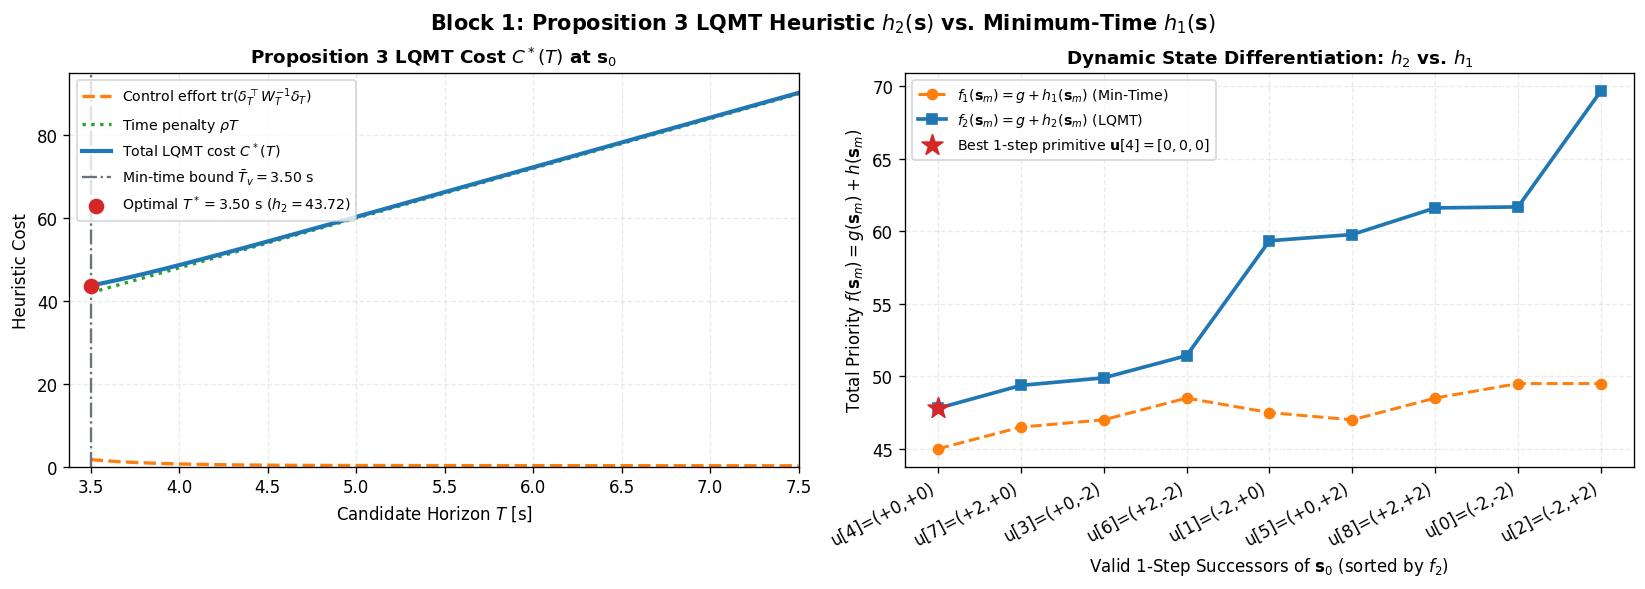

In [2]:
def W_mat(T):
    return jnp.array([
        [T**5 / 20.0, T**4 / 8.0, T**3 / 6.0],
        [T**4 / 8.0,  T**3 / 3.0, T**2 / 2.0],
        [T**3 / 6.0,  T**2 / 2.0, T],
    ])


def h_zero(s):
    return 0.0


def h_min_time(s):
    T_bar = jnp.max(jnp.abs(s_goal[0, :2] - s[0, :2])) / v_max
    return rho * T_bar


def lqmt_cost_T(s, T):
    delta = s_goal[:, :2] - F_mat(T) @ s[:, :2]
    W_inv = jnp.linalg.inv(W_mat(T))
    effort = jnp.sum(delta * (W_inv @ delta))
    return effort + rho * T


def h_lqmt(s):
    T_bar = jnp.maximum(jnp.max(jnp.abs(s_goal[0, :2] - s[0, :2])) / v_max, tau)
    T_grid = jnp.linspace(T_bar, T_bar + 4.0, 20)
    costs = jax.vmap(lqmt_cost_T, in_axes=(None, 0))(s, T_grid)
    return jnp.where(is_goal(s), 0.0, jnp.min(costs))


h0_val = float(h_zero(s0))
h1_val = float(h_min_time(s0))
h2_val = float(h_lqmt(s0))
J_star_true = 64.00

print("--- Admissibility & Tightness Check at Start State s0 ---")
print(f"h0(s0) [Dijkstra] : {h0_val:6.2f}")
print(f"h1(s0) [Min-Time] : {h1_val:6.2f}  (T_bar_v = {h1_val / rho:.3f} s)")
print(f"h2(s0) [LQMT]     : {h2_val:6.2f}")
print(f"True Optimal Cost : {J_star_true:6.2f}  (0.00 <= {h1_val:.2f} <= {h2_val:.2f} <= {J_star_true:.2f})")

# Evaluate C*(T) breakdown at s0 and 1-step successor f-values
T_bar_0 = float(jnp.max(jnp.abs(s_goal[0, :2] - s0[0, :2])) / v_max)
T_sweep = jnp.linspace(T_bar_0, T_bar_0 + 4.0, 140)
total_T = jax.vmap(lqmt_cost_T, in_axes=(None, 0))(s0, T_sweep)
time_T = rho * T_sweep
effort_T = total_T - time_T
best_T_idx = int(jnp.argmin(total_T))
T_star_0 = float(T_sweep[best_T_idx])
C_star_0 = float(total_T[best_T_idx])

s_next_0, valid_0, edge_0 = get_successors(s0)
valid_idx = jnp.where(valid_0)[0]
f_h1_valid = edge_0[valid_idx] + jax.vmap(h_min_time)(s_next_0[valid_idx])
f_h2_valid = edge_0[valid_idx] + jax.vmap(h_lqmt)(s_next_0[valid_idx])
order = jnp.argsort(f_h2_valid)
sorted_prim_ids = valid_idx[order]
f_h1_sorted = f_h1_valid[order]
f_h2_sorted = f_h2_valid[order]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13.6, 4.8), constrained_layout=True)

# Left: LQMT Cost Breakdown vs Horizon T
ax0.plot(T_sweep, effort_T, color="#ff7f0e", ls="--", lw=2.0, label=r"Control effort $\mathrm{tr}(\delta_T^\top W_T^{-1}\delta_T)$")
ax0.plot(T_sweep, time_T, color="#2ca02c", ls=":", lw=2.0, label=r"Time penalty $\rho T$")
ax0.plot(T_sweep, total_T, color="#1f77b4", lw=2.5, label=r"Total LQMT cost $C^*(T)$")
ax0.axvline(T_bar_0, color="#6b7280", ls="-.", lw=1.4, label=rf"Min-time bound $\bar{{T}}_v = {T_bar_0:.2f}$ s")
ax0.scatter([T_star_0], [C_star_0], color="#d62728", zorder=6, s=70, label=rf"Optimal $T^* = {T_star_0:.2f}$ s ($h_2 = {C_star_0:.2f}$)")
ax0.set_xlim(T_bar_0 - 0.12, float(T_sweep[-1]))
ax0.set_ylim(0.0, 95.0)
ax0.set_xlabel(r"Candidate Horizon $T$ [s]")
ax0.set_ylabel(r"Heuristic Cost")
ax0.set_title(r"Proposition 3 LQMT Cost $C^*(T)$ at $\mathbf{s}_0$")
ax0.legend(loc="upper left", frameon=True)

# Right: 1-Step Successor Priority f(s_m) = g(s_m) + h(s_m)
x_pos = jnp.arange(len(sorted_prim_ids))
labels = [
    f"u[{int(i)}]=({int(U_M[int(i), 0]):+d},{int(U_M[int(i), 1]):+d})"
    for i in sorted_prim_ids
]
best_prim_id = int(sorted_prim_ids[0])
best_u_xy = (int(U_M[best_prim_id, 0]), int(U_M[best_prim_id, 1]))
ax1.plot(x_pos, f_h1_sorted, "o--", color="#ff7f0e", lw=1.8, ms=6, label=r"$f_1(\mathbf{s}_m) = g + h_1(\mathbf{s}_m)$ (Min-Time)")
ax1.plot(x_pos, f_h2_sorted, "s-", color="#1f77b4", lw=2.2, ms=6.5, label=r"$f_2(\mathbf{s}_m) = g + h_2(\mathbf{s}_m)$ (LQMT)")
ax1.scatter(
    [0], [float(f_h2_sorted[0])], color="#d62728", marker="*", s=170, zorder=6,
    label=rf"Best 1-step primitive $\mathbf{{u}}[{best_prim_id}]=[{best_u_xy[0]}, {best_u_xy[1]}, 0]$",
)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels, rotation=28, ha="right")
ax1.set_xlabel(r"Valid 1-Step Successors of $\mathbf{s}_0$ (sorted by $f_2$)")
ax1.set_ylabel(r"Total Priority $f(\mathbf{s}_m) = g(\mathbf{s}_m) + h(\mathbf{s}_m)$")
ax1.set_title(r"Dynamic State Differentiation: $h_2$ vs. $h_1$")
ax1.legend(loc="upper left", frameon=True)

fig.suptitle(r"Block 1: Proposition 3 LQMT Heuristic $h_2(\mathbf{s})$ vs. Minimum-Time $h_1(\mathbf{s})$", fontsize=12.5, fontweight="bold")
plt.show()


---
## Block 2: Fully Tensorized Pure-JAX Wavefront Search (Sec. III-C, Figs. 5 & 8)

Instead of maintaining a Python `heapq` priority queue, we run the entire best-first graph search inside XLA via `jax.lax.while_loop` over fixed-capacity arrays (`MAX_NODES = 2500`):

- **Exact Integer Lattice Key (`encode_xy`)**: Because $\tau = 0.5\,\text{s}$ and $j_{\max} = 2.0\,\text{m/s}^3$, every reachable horizontal lattice state $(p_x, p_y, v_x, v_y, a_x, a_y)$ lies on the exact rational grid $\frac{1}{24}\mathbb{Z}^2 \times \frac{1}{4}\mathbb{Z}^2 \times \frac{1}{4}\mathbb{Z}^2$, enabling exact integer key lookup across `MAX_NODES = 2500` slots on the GPU.
- **Wavefront Selection**: Each iteration selects the open lattice node with minimum total priority via `curr_idx = jnp.argmin(f_cost)`, checks `is_goal(states[curr_idx])`, and marks `curr_idx` closed by setting `f_cost[curr_idx] = jnp.inf`.
- **Parallel Expansion**: `get_successors(s_curr)` and `jax.vmap(heuristic_fn)(s_next_all)` evaluate all $M = 9$ cubic trajectories, check collision against all 6 cylindrical obstacles across 11 sub-steps, and update open lattice slots via `jax.lax.fori_loop`.


In [3]:
MAX_NODES = 2500


def encode_xy(s):
    return jnp.concatenate([
        jnp.round(s[0, :2] * 24.0),
        jnp.round(s[1, :2] * 4.0),
        jnp.round(s[2, :2] * 4.0),
    ]).astype(jnp.int32)


def run_jax_search(heuristic_fn):
    states = jnp.full((MAX_NODES, 3, 3), jnp.inf).at[0].set(s0)
    keys = jnp.full((MAX_NODES, 6), -999999, dtype=jnp.int32).at[0].set(encode_xy(s0))
    g_cost = jnp.full((MAX_NODES,), jnp.inf).at[0].set(0.0)
    f_cost = jnp.full((MAX_NODES,), jnp.inf).at[0].set(heuristic_fn(s0))
    closed = jnp.zeros((MAX_NODES,), dtype=bool)
    parent = jnp.full((MAX_NODES,), -1, dtype=jnp.int32)
    parent_u = jnp.full((MAX_NODES,), -1, dtype=jnp.int32)

    def cond_fn(carry):
        states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = carry
        return (goal_idx < 0) & (jnp.min(f_cost) < jnp.inf) & (n_alloc < MAX_NODES - 9)

    def body_fn(carry):
        states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = carry
        curr_idx = jnp.argmin(f_cost).astype(jnp.int32)
        s_curr = states[curr_idx]
        g_curr = g_cost[curr_idx]

        reached = is_goal(s_curr)
        goal_idx = jnp.where(reached, curr_idx, goal_idx)
        f_cost = f_cost.at[curr_idx].set(jnp.inf)
        closed = closed.at[curr_idx].set(True)
        n_exp = n_exp + jnp.where(reached, 0, 1)

        s_next_all, valid_all, edge_costs = get_successors(s_curr)
        h_all = jax.vmap(heuristic_fn)(s_next_all)
        keys_next_all = jax.vmap(encode_xy)(s_next_all)

        def insert_one(m, inner_carry):
            states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc = inner_carry
            valid = valid_all[m] & (~reached)
            s_m = s_next_all[m]
            key_m = keys_next_all[m]
            new_g = g_curr + edge_costs[m]
            new_f = new_g + h_all[m]

            matches = jnp.all(keys == key_m[None, :], axis=-1)
            exists = jnp.any(matches)
            target_idx = jnp.where(exists, jnp.argmax(matches).astype(jnp.int32), n_alloc)
            improve = valid & ((~exists) | ((new_g < g_cost[target_idx]) & (~closed[target_idx])))

            states = jnp.where(improve & (~exists), states.at[target_idx].set(s_m), states)
            keys = jnp.where(improve & (~exists), keys.at[target_idx].set(key_m), keys)
            g_cost = jnp.where(improve, g_cost.at[target_idx].set(new_g), g_cost)
            f_cost = jnp.where(improve, f_cost.at[target_idx].set(new_f), f_cost)
            parent = jnp.where(improve, parent.at[target_idx].set(curr_idx), parent)
            parent_u = jnp.where(improve, parent_u.at[target_idx].set(m), parent_u)
            n_alloc = n_alloc + jnp.where(improve & (~exists), 1, 0)
            return (states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc)

        states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc = jax.lax.fori_loop(
            0, 9, insert_one, (states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc)
        )
        return (states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx)

    init_carry = (states, keys, g_cost, f_cost, closed, parent, parent_u, jnp.int32(1), jnp.int32(0), jnp.int32(-1))
    return jax.lax.while_loop(cond_fn, body_fn, init_carry)


def extract_optimal_trajectory(states, parent, parent_u, goal_idx):
    node_chain, u_indices = [int(goal_idx)], []
    curr = int(goal_idx)
    while int(parent[curr]) >= 0:
        u_indices.append(int(parent_u[curr]))
        curr = int(parent[curr])
        node_chain.append(curr)
    node_chain.reverse()
    u_indices.reverse()
    return states[jnp.array(node_chain)], U_M[jnp.array(u_indices)]


search_results = {}
print("--- Pure-JAX 6-Cylinder Slalom Jerk Lattice Search Benchmark (n=3, M=9) ---")
for label, h_fn in [
    ("Dijkstra (h=0)", h_zero),
    ("A* with h1 (Min-Time)", h_min_time),
    ("A* with h2 (LQMT)", h_lqmt),
]:
    jit_search = jax.jit(lambda h=h_fn: run_jax_search(h))
    out = jit_search()
    jax.block_until_ready(out[-1])

    t0 = time.perf_counter()
    out = jit_search()
    jax.block_until_ready(out[-1])
    warm_ms = (time.perf_counter() - t0) * 1000.0

    states, keys, g_cost, f_cost, closed, parent, parent_u, n_alloc, n_exp, goal_idx = out
    g_opt = float(g_cost[int(goal_idx)])
    search_results[label] = {
        "states": states,
        "g_cost": g_cost,
        "closed": closed,
        "parent": parent,
        "parent_u": parent_u,
        "n_alloc": int(n_alloc),
        "n_exp": int(n_exp),
        "goal_idx": int(goal_idx),
        "g_opt": g_opt,
        "warm_ms": warm_ms,
    }
    print(
        f"{label:22s} | optimal_cost={g_opt:6.2f} | expanded={int(n_exp):4d} "
        f"| allocated={int(n_alloc):4d} | warm_GPU={warm_ms:6.2f} ms"
    )

res_h2 = search_results["A* with h2 (LQMT)"]
knots_opt, u_opt = extract_optimal_trajectory(
    res_h2["states"], res_h2["parent"], res_h2["parent_u"], res_h2["goal_idx"]
)
red_vs_dijkstra = search_results["Dijkstra (h=0)"]["n_exp"] / res_h2["n_exp"]
red_vs_h1 = search_results["A* with h1 (Min-Time)"]["n_exp"] / res_h2["n_exp"]
print(f"\nNode expansion reduction of h2 (LQMT): {red_vs_dijkstra:.1f}x vs Dijkstra, {red_vs_h1:.1f}x vs h1 (Min-Time)")
print(f"Recovered optimal {u_opt.shape[0]}-stage jerk sequence u_opt (shape {u_opt.shape}, T* = {u_opt.shape[0] * tau:.1f} s):\n{u_opt}")


--- Pure-JAX 6-Cylinder Slalom Jerk Lattice Search Benchmark (n=3, M=9) ---


Dijkstra (h=0)         | optimal_cost= 64.00 | expanded=1316 | allocated=1861 | warm_GPU=2696.21 ms


A* with h1 (Min-Time)  | optimal_cost= 64.00 | expanded= 104 | allocated= 285 | warm_GPU=274.20 ms


A* with h2 (LQMT)      | optimal_cost= 64.00 | expanded=  26 | allocated=  81 | warm_GPU=  6.32 ms



Node expansion reduction of h2 (LQMT): 50.6x vs Dijkstra, 4.0x vs h1 (Min-Time)
Recovered optimal 8-stage jerk sequence u_opt (shape (8, 3), T* = 4.0 s):
[[ 0. -2.  0.]
 [ 2.  0.  0.]
 [-2.  2.  0.]
 [ 0.  2.  0.]
 [ 0.  0.  0.]
 [ 0. -2.  0.]
 [ 0. -2.  0.]
 [ 0.  2.  0.]]


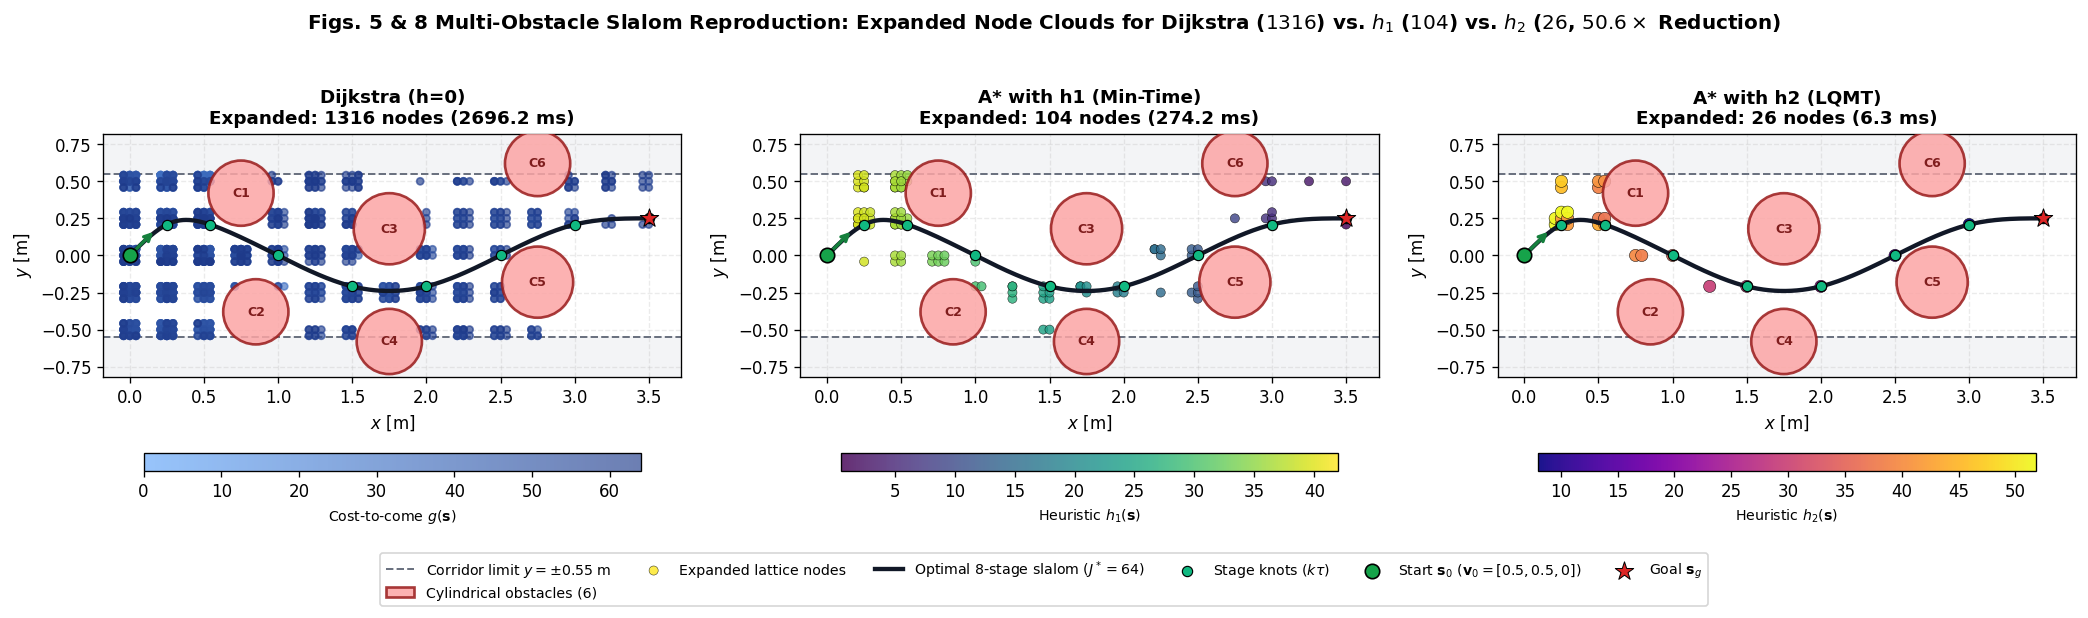

In [4]:
# Dense evaluation of the 8-stage optimal S-curve trajectory for plotting
t_dense_seg = jnp.linspace(0.0, tau, 41)


def sample_full_trajectory(knots, u_seq):
    segs = [
        jax.vmap(lambda t: F_mat(t) @ knots[k] + jnp.outer(G_vec(t), u_seq[k]))(t_dense_seg)
        for k in range(u_seq.shape[0])
    ]
    t_all = jnp.concatenate([k * tau + t_dense_seg for k in range(u_seq.shape[0])])
    s_all = jnp.concatenate(segs, axis=0)
    return t_all, s_all


t_opt_dense, s_opt_dense = sample_full_trajectory(knots_opt, u_opt)
p_opt_dense = s_opt_dense[:, 0, :]

fig, axes = plt.subplots(1, 3, figsize=(17.4, 4.2), constrained_layout=True)
fig.set_constrained_layout_pads(w_pad=0.10, h_pad=0.06, wspace=0.04, hspace=0.04)

configs = [
    ("Dijkstra (h=0)", h_zero, "Blues", r"Cost-to-come $g(\mathbf{s})$"),
    ("A* with h1 (Min-Time)", h_min_time, "viridis", r"Heuristic $h_1(\mathbf{s})$"),
    ("A* with h2 (LQMT)", h_lqmt, "plasma", r"Heuristic $h_2(\mathbf{s})$"),
]

for idx, (ax, (label, h_fn, cmap_name, cbar_label)) in enumerate(zip(axes, configs)):
    res = search_results[label]
    exp_mask = res["closed"].at[res["goal_idx"]].set(False)
    exp_states = res["states"][exp_mask]
    exp_pos = exp_states[:, 0, :]

    # Corridor boundaries y = +/- 0.55 m
    ax.axhspan(0.55, 0.85, color="#f3f4f6", zorder=0)
    ax.axhspan(-0.85, -0.55, color="#f3f4f6", zorder=0)
    ax.axhline(0.55, color="#6b7280", ls="--", lw=1.2, zorder=1, label=r"Corridor limit $y=\pm 0.55$ m")
    ax.axhline(-0.55, color="#6b7280", ls="--", lw=1.2, zorder=1)

    # 6 Cylindrical Obstacles (2D top-down cross-sections)
    for c_idx in range(cyl_xy.shape[0]):
        cx, cy = float(cyl_xy[c_idx, 0]), float(cyl_xy[c_idx, 1])
        cr = float(cyl_radii[c_idx])
        circ = Circle(
            (cx, cy), cr, facecolor="#fca5a5", edgecolor="#991b1b",
            lw=1.6, alpha=0.85, zorder=3,
            label="Cylindrical obstacles (6)" if c_idx == 0 else None,
        )
        ax.add_patch(circ)
        ax.text(cx, cy, f"C{c_idx + 1}", ha="center", va="center", fontsize=7.5, fontweight="bold", color="#7f1d1d", zorder=4)

    # Expanded lattice states
    if label == "Dijkstra (h=0)":
        c_vals = res["g_cost"][exp_mask]
        dijkstra_cmap = LinearSegmentedColormap.from_list("dijkstra_blues", ["#60a5fa", "#1e3a8a"])
        sc = ax.scatter(
            exp_pos[:, 0], exp_pos[:, 1],
            c=c_vals, cmap=dijkstra_cmap, vmin=0.0, vmax=64.0, s=18, alpha=0.65,
            zorder=2, label="Expanded lattice nodes",
        )
    else:
        c_vals = jax.vmap(h_fn)(exp_states)
        sc = ax.scatter(
            exp_pos[:, 0], exp_pos[:, 1],
            c=c_vals, cmap=cmap_name, s=30 if res["n_exp"] > 50 else 54,
            alpha=0.82 if res["n_exp"] > 50 else 0.95, edgecolors="black", linewidths=0.3,
            zorder=2, label="Expanded lattice nodes",
        )
    cbar = fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.86, pad=0.05, aspect=28)
    cbar.set_label(cbar_label, fontsize=8.5)

    # Optimal S-curve trajectory and stage knots
    ax.plot(
        p_opt_dense[:, 0], p_opt_dense[:, 1],
        color="#111827", lw=2.6, zorder=5, label=r"Optimal 8-stage slalom ($J^*=64$)",
    )
    ax.scatter(
        knots_opt[:, 0, 0], knots_opt[:, 0, 1],
        color="#10b981", s=38, edgecolor="black", lw=0.7, zorder=6, label=r"Stage knots ($k\tau$)",
    )
    # Initial velocity arrow v0
    ax.annotate(
        "", xy=(float(s0[0, 0] + 0.35 * s0[1, 0]), float(s0[0, 1] + 0.35 * s0[1, 1])),
        xytext=(float(s0[0, 0]), float(s0[0, 1])),
        arrowprops=dict(arrowstyle="->", color="#15803d", lw=2.0),
        zorder=7,
    )
    ax.scatter([s0[0, 0]], [s0[0, 1]], color="#16a34a", s=75, marker="o", edgecolor="black", zorder=7, label=r"Start $\mathbf{s}_0$ ($\mathbf{v}_0=[0.5,0.5,0]$)")
    ax.scatter([s_goal[0, 0]], [s_goal[0, 1]], color="#dc2626", s=135, marker="*", edgecolor="black", lw=0.6, zorder=7, label=r"Goal $\mathbf{s}_g$")

    ax.set_xlim(-0.18, 3.72)
    ax.set_ylim(-0.82, 0.82)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x$ [m]")
    ax.set_ylabel(r"$y$ [m]")
    ax.set_title(f"{label}\nExpanded: {res['n_exp']} nodes ({res['warm_ms']:.1f} ms)")

handles, labels_leg = axes[1].get_legend_handles_labels()
fig.legend(
    handles, labels_leg, loc="upper center", bbox_to_anchor=(0.5, -0.03),
    ncol=6, fontsize=8.5, frameon=True,
)
fig.suptitle(
    r"Figs. 5 & 8 Multi-Obstacle Slalom Reproduction: Expanded Node Clouds for Dijkstra ($1316$) vs. $h_1$ ($104$) vs. $h_2$ ($26$, $50.6\times$ Reduction)",
    fontsize=12.0,
    fontweight="bold",
    y=1.03,
)
plt.show()


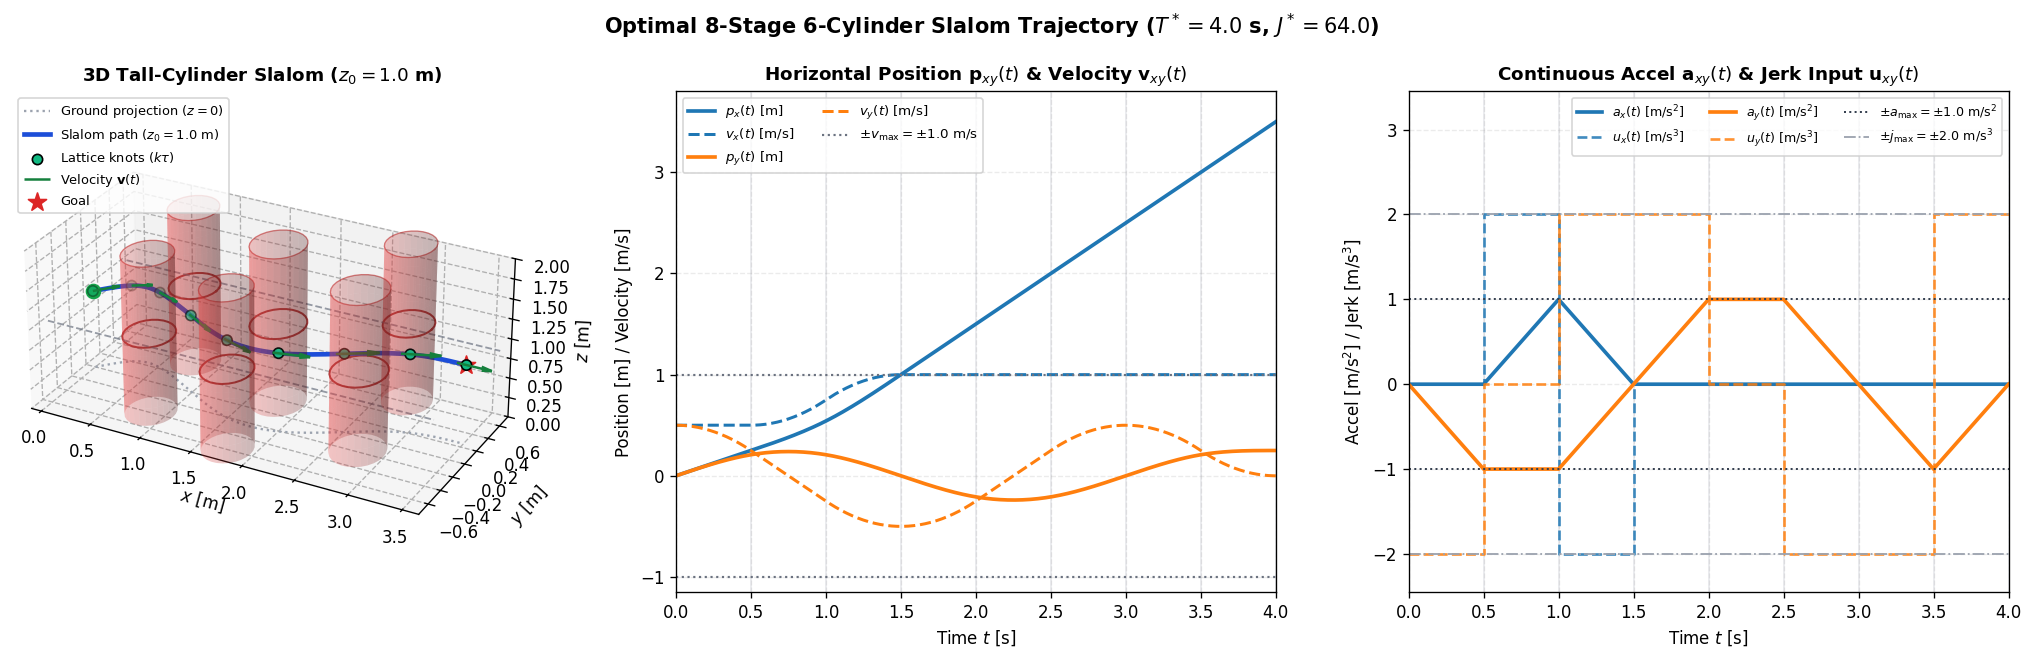

In [5]:
v_opt_dense = s_opt_dense[:, 1, :]
a_opt_dense = s_opt_dense[:, 2, :]
t_knots = jnp.arange(knots_opt.shape[0]) * tau
T_total = float(t_knots[-1])

fig = plt.figure(figsize=(17.6, 5.5), constrained_layout=True)
fig.set_constrained_layout_pads(w_pad=0.22, h_pad=0.10, wspace=0.06, hspace=0.06)
ax0 = fig.add_subplot(1, 3, 1, projection="3d")
ax1 = fig.add_subplot(1, 3, 2)
ax2 = fig.add_subplot(1, 3, 3)

# Panel 1: 3D tall-cylinder perspective view of the 6 pillars and constant-altitude S-curve slalom
theta_cyl = jnp.linspace(0.0, 2.0 * jnp.pi, 28)
z_cyl = jnp.linspace(cyl_z_min, cyl_z_max, 10)
theta_grid, z_grid = jnp.meshgrid(theta_cyl, z_cyl)

for c_idx in range(cyl_xy.shape[0]):
    cx, cy = float(cyl_xy[c_idx, 0]), float(cyl_xy[c_idx, 1])
    cr = float(cyl_radii[c_idx])
    xc = cx + cr * jnp.cos(theta_grid)
    yc = cy + cr * jnp.sin(theta_grid)
    ax0.plot_surface(xc, yc, z_grid, color="#ef4444", alpha=0.28, edgecolor="none")
    # Draw top & bottom cylinder rings at z=0 and z=2 and intersection ring at z=z0=1.0 m
    ax0.plot(cx + cr * jnp.cos(theta_cyl), cy + cr * jnp.sin(theta_cyl), jnp.full_like(theta_cyl, z0), color="#991b1b", lw=1.2, alpha=0.85)
    ax0.plot(cx + cr * jnp.cos(theta_cyl), cy + cr * jnp.sin(theta_cyl), jnp.full_like(theta_cyl, cyl_z_max), color="#b91c1c", lw=0.8, alpha=0.55)

# Corridor boundary rails at altitude z0 = 1.0 m
ax0.plot([-0.05, 3.65], [0.55, 0.55], [z0, z0], color="#6b7280", ls="--", lw=1.1, alpha=0.7)
ax0.plot([-0.05, 3.65], [-0.55, -0.55], [z0, z0], color="#6b7280", ls="--", lw=1.1, alpha=0.7)

# Optimal trajectory at z0 = 1.0 m and ground projection at z = 0.0 m
ax0.plot(p_opt_dense[:, 0], p_opt_dense[:, 1], jnp.zeros_like(p_opt_dense[:, 2]), color="#9ca3af", ls=":", lw=1.4, label="Ground projection ($z=0$)")
ax0.plot(p_opt_dense[:, 0], p_opt_dense[:, 1], p_opt_dense[:, 2], color="#1d4ed8", lw=2.8, label=rf"Slalom path ($z_0={z0:.1f}$ m)")
ax0.scatter(
    knots_opt[:, 0, 0], knots_opt[:, 0, 1], knots_opt[:, 0, 2],
    color="#10b981", s=38, edgecolor="black", zorder=6, label=r"Lattice knots ($k\tau$)",
)
stride = 40
ax0.quiver(
    p_opt_dense[::stride, 0], p_opt_dense[::stride, 1], p_opt_dense[::stride, 2],
    v_opt_dense[::stride, 0], v_opt_dense[::stride, 1], v_opt_dense[::stride, 2],
    length=0.32, normalize=False, color="#15803d", lw=1.5, label=r"Velocity $\mathbf{v}(t)$",
)
ax0.scatter([s0[0, 0]], [s0[0, 1]], [s0[0, 2]], color="#16a34a", s=70, marker="o")
ax0.scatter([s_goal[0, 0]], [s_goal[0, 1]], [s_goal[0, 2]], color="#dc2626", s=130, marker="*", label="Goal")
ax0.set_xlim(-0.10, 3.65)
ax0.set_ylim(-0.75, 0.75)
ax0.set_zlim(0.0, 2.0)
ax0.set_box_aspect((1.95, 0.95, 0.80))
ax0.set_xlabel(r"$x$ [m]", labelpad=4)
ax0.set_ylabel(r"$y$ [m]", labelpad=4)
ax0.set_zlabel(r"$z$ [m]", labelpad=2)
ax0.view_init(elev=28, azim=-62)
ax0.set_title(r"3D Tall-Cylinder Slalom ($z_0 = 1.0$ m)")
ax0.legend(loc="upper left", fontsize=7.8, frameon=True)

# Panel 2: Position (p_x, p_y) and Bounded Velocity (v_x, v_y) vs Time
axis_colors = ["#1f77b4", "#ff7f0e"]
axis_names = ["x", "y"]
for d in range(2):
    ax1.plot(t_opt_dense, p_opt_dense[:, d], color=axis_colors[d], lw=2.2, label=rf"$p_{axis_names[d]}(t)$ [m]")
    ax1.plot(t_opt_dense, v_opt_dense[:, d], color=axis_colors[d], lw=1.8, ls="--", label=rf"$v_{axis_names[d]}(t)$ [m/s]")
ax1.axhline(v_max, color="#6b7280", ls=":", lw=1.3, label=rf"$\pm v_{{\max}} = \pm {v_max:.1f}$ m/s")
ax1.axhline(-v_max, color="#6b7280", ls=":", lw=1.3)
for tk in t_knots:
    ax1.axvline(float(tk), color="#e5e7eb", lw=0.9, zorder=0)
ax1.set_xlim(0.0, T_total)
ax1.set_ylim(-1.15, 3.80)
ax1.set_xlabel(r"Time $t$ [s]")
ax1.set_ylabel(r"Position [m] / Velocity [m/s]")
ax1.set_title(r"Horizontal Position $\mathbf{p}_{xy}(t)$ & Velocity $\mathbf{v}_{xy}(t)$")
ax1.legend(loc="upper left", ncol=2, fontsize=8, frameon=True)

# Panel 3: Continuous Acceleration (a_x, a_y) and Piecewise-Constant Jerk (u_x, u_y)
t_step = jnp.append(t_knots[:-1], T_total)
u_step = jnp.vstack([u_opt, u_opt[-1:]])
for d in range(2):
    ax2.plot(t_opt_dense, a_opt_dense[:, d], color=axis_colors[d], lw=2.2, label=rf"$a_{axis_names[d]}(t)$ [m/s$^2$]")
    ax2.step(t_step, u_step[:, d], where="post", color=axis_colors[d], lw=1.6, ls="--", alpha=0.85, label=rf"$u_{axis_names[d]}(t)$ [m/s$^3$]")
ax2.axhline(a_max, color="#374151", ls=":", lw=1.2, label=rf"$\pm a_{{\max}} = \pm {a_max:.1f}$ m/s$^2$")
ax2.axhline(-a_max, color="#374151", ls=":", lw=1.2)
ax2.axhline(j_max, color="#9ca3af", ls="-.", lw=1.1, label=rf"$\pm j_{{\max}} = \pm {j_max:.1f}$ m/s$^3$")
ax2.axhline(-j_max, color="#9ca3af", ls="-.", lw=1.1)
for tk in t_knots:
    ax2.axvline(float(tk), color="#e5e7eb", lw=0.9, zorder=0)
ax2.set_xlim(0.0, T_total)
ax2.set_ylim(-2.45, 3.45)
ax2.set_xlabel(r"Time $t$ [s]")
ax2.set_ylabel(r"Accel [m/s$^2$] / Jerk [m/s$^3$]")
ax2.set_title(r"Continuous Accel $\mathbf{a}_{xy}(t)$ & Jerk Input $\mathbf{u}_{xy}(t)$")
ax2.legend(loc="upper right", ncol=3, fontsize=7.6, frameon=True)

fig.suptitle(
    rf"Optimal {u_opt.shape[0]}-Stage 6-Cylinder Slalom Trajectory ($T^* = {T_total:.1f}$ s, $J^* = 64.0$)",
    fontsize=12.5,
    fontweight="bold",
)
plt.show()
